<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [108]:
import random

In [109]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [110]:
len(l)

10000

In [111]:
l[:5]

[8, 11, 8, 8, 5]

In [112]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0286
3     0.0508
4     0.0884
5     0.1127
6     0.1367
7     0.1701
8     0.1345
9     0.1086
10    0.0829
11    0.0570
12    0.0297
Name: count, dtype: float64


<Axes: >

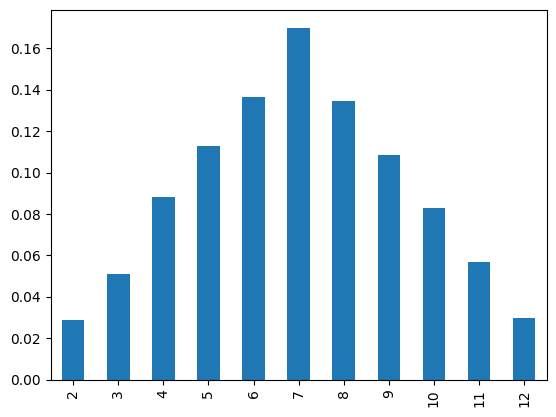

In [113]:
s.plot(kind='bar')

<Axes: >

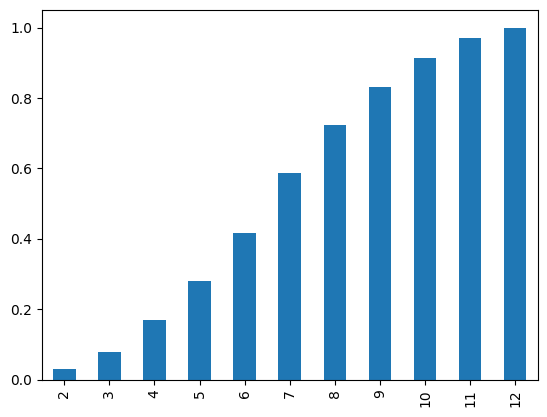

In [114]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [115]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[51.22579964 47.84381224 41.36219234 60.22795636 53.81780176 55.32816922
 44.54587201 50.34359153 60.35347658 37.79445027 51.24640897 57.84836041
 48.3180525  58.23349006 42.61550819 49.5018975  51.25472697 44.30323832
 46.87575491 52.38134172 47.13049658 50.98906806 50.51052158 54.45892613
 46.16596138 50.2762975  39.21771764 53.31148848 52.8738577  48.54434363
 44.72526793 45.14538464 57.56748033 50.7993316  48.36030821 49.09312548
 60.17596586 54.5572667  56.98416727 49.73338747 48.50287357 46.96382932
 55.46294992 50.91449434 53.12806864 44.36112844 54.1783864  44.90103165
 46.12424136 63.76906354 46.63575713 52.6029817  42.37875373 53.13384716
 43.08301453 50.57611964 59.70436227 52.04202339 45.59517924 56.93604173
 48.98896378 57.25789486 50.88287868 48.40259555 60.27654444 50.04460074
 46.51804032 46.64560147 44.71250954 46.37925897 48.13528088 46.2795197
 51.87266056 49.89216858 44.65913651 41.19143913 61.09088944 57.17853716
 50.55353883 51.15178473 56.66189702 48.5620483  50.

In [116]:
sample.mean()

np.float64(49.97299319118337)

(array([ 11.,  21.,  84., 191., 228., 220., 140.,  72.,  29.,   4.]),
 array([34.75095957, 37.8678916 , 40.98482362, 44.10175565, 47.21868768,
        50.3356197 , 53.45255173, 56.56948376, 59.68641578, 62.80334781,
        65.92027984]),
 <BarContainer object of 10 artists>)

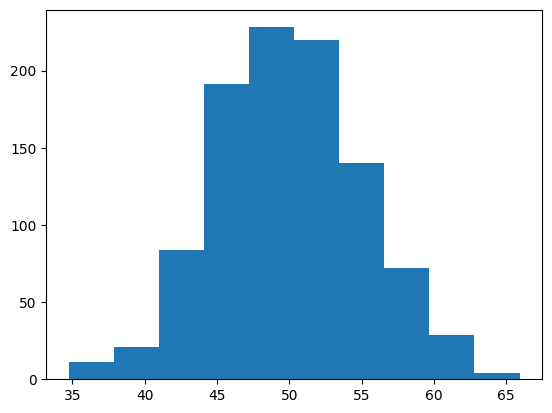

In [117]:
plt.hist(sample,bins=10)

In [118]:
sample_mean=sample.mean()
sample_std=sample.std()

In [119]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [120]:
sample.min()

np.float64(34.75095957172768)

In [121]:
sample.max()

np.float64(65.92027983729791)

In [122]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [123]:
probabilities=[dist.pdf(value) for value in values]

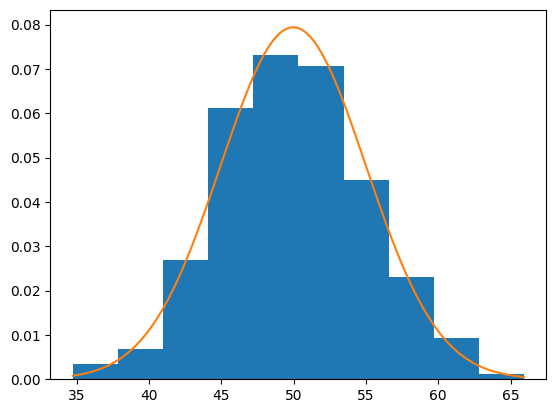

In [124]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_876/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

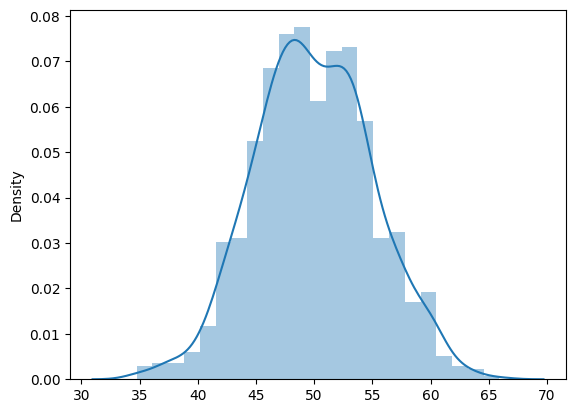

In [125]:
import seaborn as sns
sns.distplot(sample)

KDE

In [126]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [127]:
sample

array([13.97590859, 11.53383643, 18.78399791, 26.26418003, 23.61620524,
       21.44090976, 20.19512302, 20.42754437, 19.95309424,  9.34165618,
       29.45020255, 23.91246922, 19.33771408, 26.61068197, 18.48717492,
       17.56446621, 22.40336965, 20.71276052, 20.48736425, 19.42269471,
       23.17277601, 12.30960855, 24.60291503, 25.29527935, 20.97249036,
       22.55167585, 11.19004403, 17.64639821, 15.96333976, 28.2907051 ,
       24.30738369, 22.83632389, 24.52069724, 27.47897041, 17.32620425,
       22.21286654, 26.19910707, 18.13732325, 27.0413288 , 25.52356585,
       34.71440966, 25.96916104, 13.76936907, 21.64754739, 20.48206418,
       16.99396628, 24.24910155, 17.78096413, 25.93525116, 16.46572466,
       14.12231852, 16.7852115 , 24.00696017, 14.28731364, 14.08561724,
       21.72643717, 14.56359222, 16.95648311, 13.69588474, 30.75163404,
       21.06206628, 22.87883413, 20.90115745, 29.32926434, 18.77689885,
       28.00369775, 14.76769393, 24.67007805, 22.5082149 , 24.19

(array([ 2.,  1.,  4.,  2.,  4.,  8., 11., 13., 13., 20., 16., 20., 18.,
        17., 25., 24., 16., 21., 19., 11., 16., 11., 20., 12., 12., 13.,
        14., 24., 27., 38., 42., 52., 61., 44., 51., 46., 37., 57., 35.,
        30., 34., 24.,  8., 11.,  3.,  3.,  3.,  5.,  0.,  2.]),
 array([ 6.59216252,  7.58176039,  8.57135827,  9.56095615, 10.55055403,
        11.54015191, 12.52974979, 13.51934767, 14.50894555, 15.49854342,
        16.4881413 , 17.47773918, 18.46733706, 19.45693494, 20.44653282,
        21.4361307 , 22.42572858, 23.41532646, 24.40492433, 25.39452221,
        26.38412009, 27.37371797, 28.36331585, 29.35291373, 30.34251161,
        31.33210949, 32.32170737, 33.31130524, 34.30090312, 35.290501  ,
        36.28009888, 37.26969676, 38.25929464, 39.24889252, 40.2384904 ,
        41.22808828, 42.21768615, 43.20728403, 44.19688191, 45.18647979,
        46.17607767, 47.16567555, 48.15527343, 49.14487131, 50.13446919,
        51.12406706, 52.11366494, 53.10326282, 54.0928607 ,

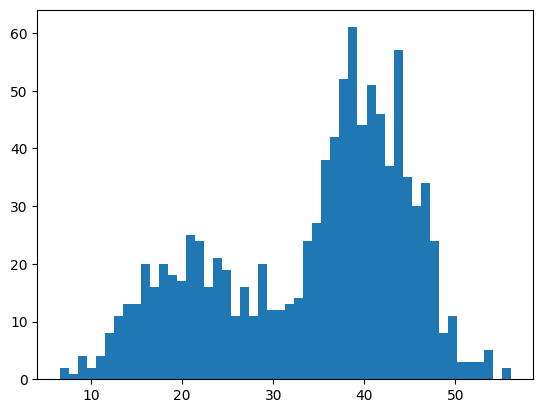

In [128]:
plt.hist(sample,bins=50)

In [129]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [130]:
dataset=sns.load_dataset("iris")

In [131]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

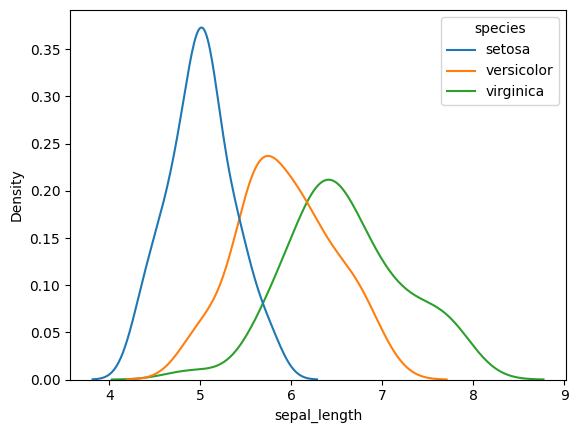

In [132]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

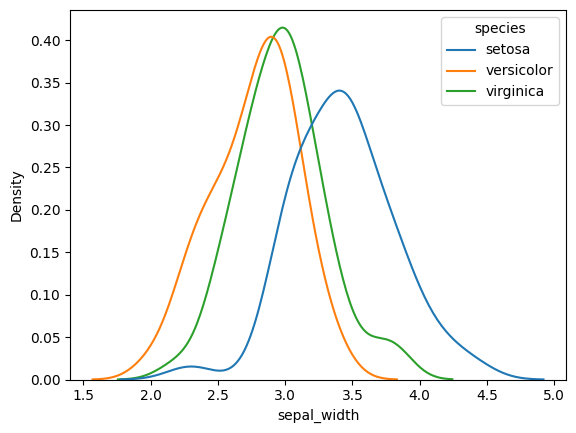

In [133]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

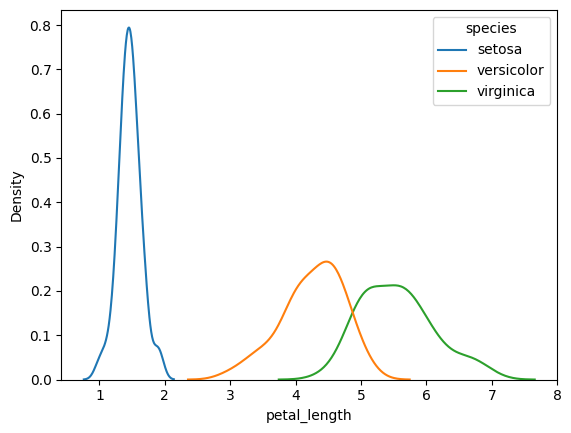

In [134]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

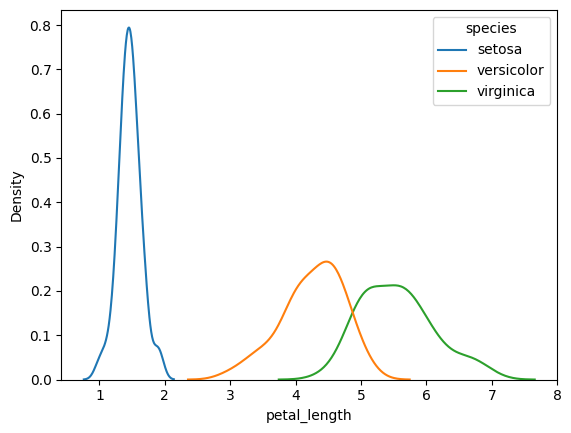

In [135]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [136]:
tips=sns.load_dataset("tips")

In [137]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

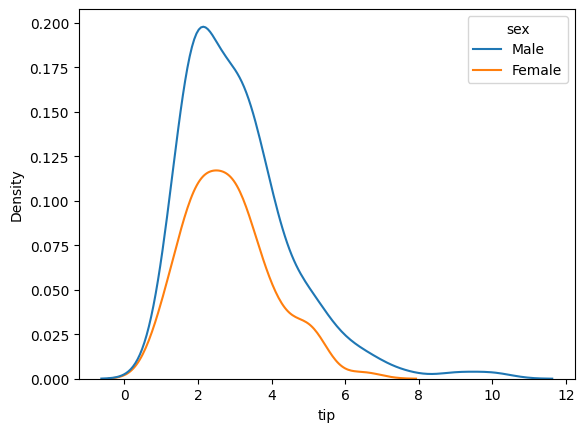

In [138]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

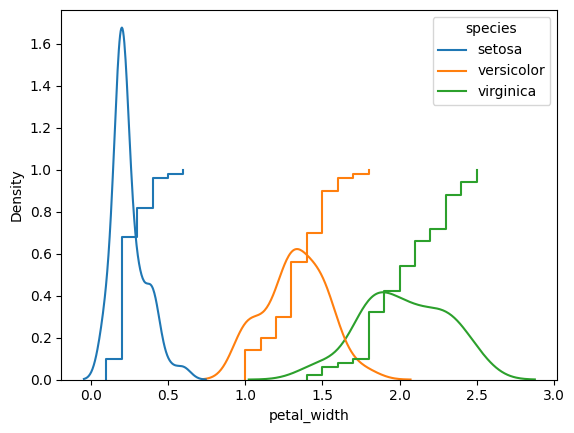

In [139]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [140]:
#contour plots

How to find distribution is normal or not?

In [141]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

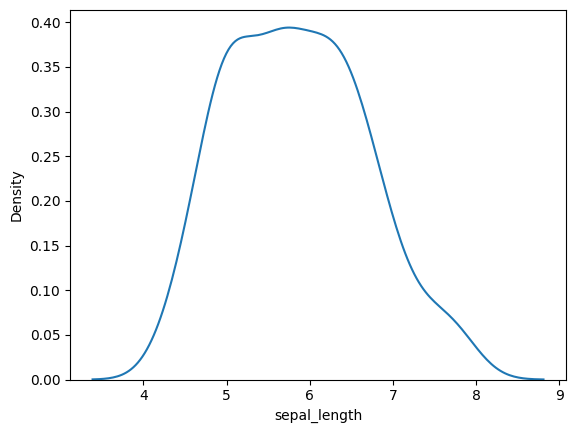

In [142]:
sns.kdeplot(iris["sepal_length"])

In [143]:
temp=sorted(iris['sepal_length'].tolist())

In [144]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [145]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [146]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

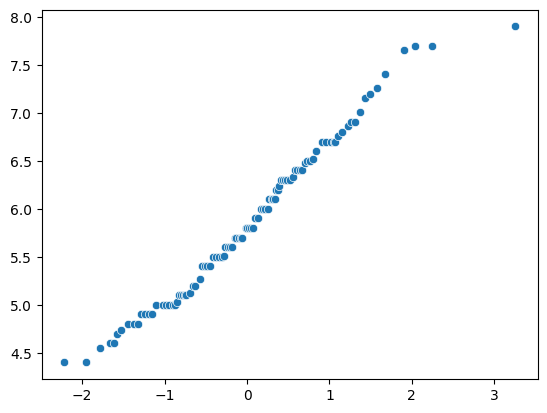

In [147]:
sns.scatterplot(x=x_quant,y=y_quant)

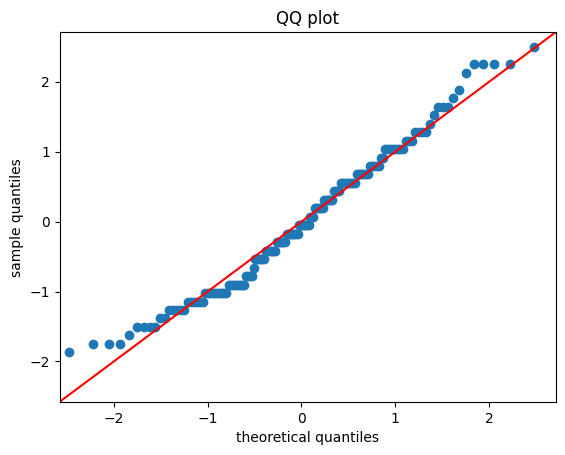

In [148]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [149]:
import scipy.stats as stats

In [150]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 99.,  96.,  98.,  96.,  96., 108., 111., 107.,  90.,  99.]),
 array([1.94837610e-04, 1.00140501e-01, 2.00086164e-01, 3.00031827e-01,
        3.99977490e-01, 4.99923153e-01, 5.99868816e-01, 6.99814479e-01,
        7.99760142e-01, 8.99705805e-01, 9.99651468e-01]),
 <BarContainer object of 10 artists>)

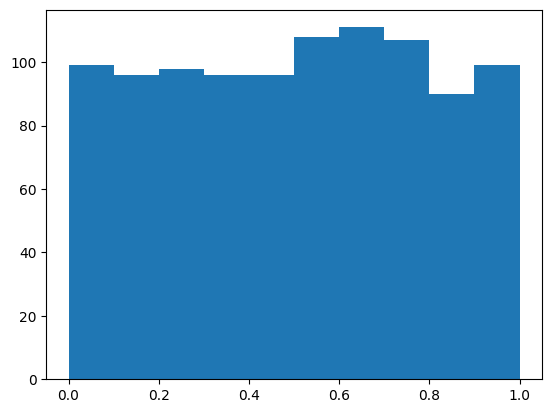

In [151]:
plt.hist(x)

PARETO DISTRIBUTION

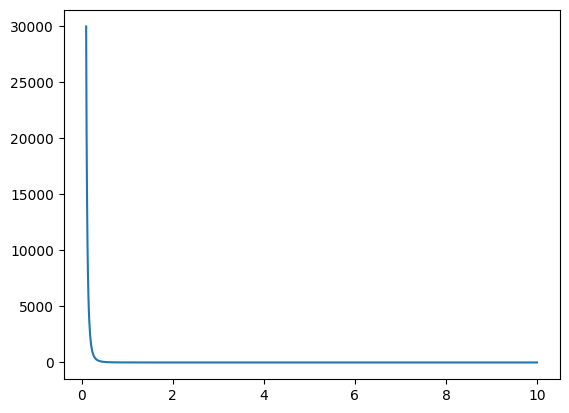

In [152]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

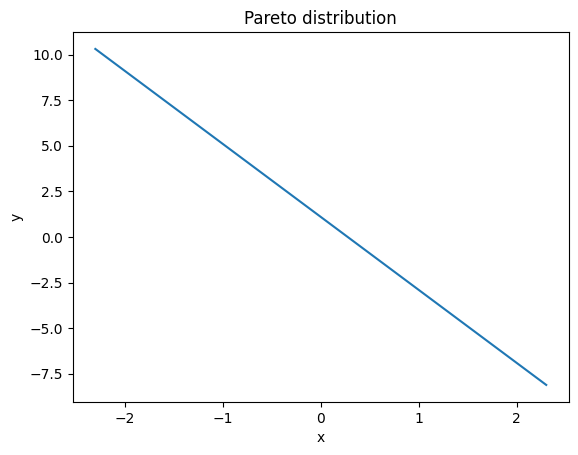

In [153]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [154]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([915.,  62.,  10.,   5.,   5.,   1.,   0.,   0.,   1.,   1.]),
 array([ 1.00041489,  3.58067007,  6.16092525,  8.74118043, 11.32143561,
        13.90169079, 16.48194598, 19.06220116, 21.64245634, 24.22271152,
        26.8029667 ]),
 <BarContainer object of 10 artists>)

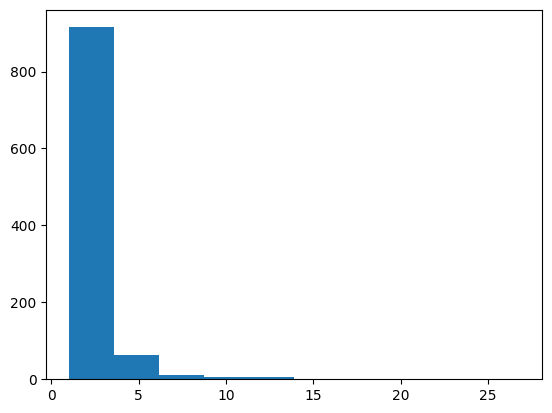

In [155]:
plt.hist(x)

In [156]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

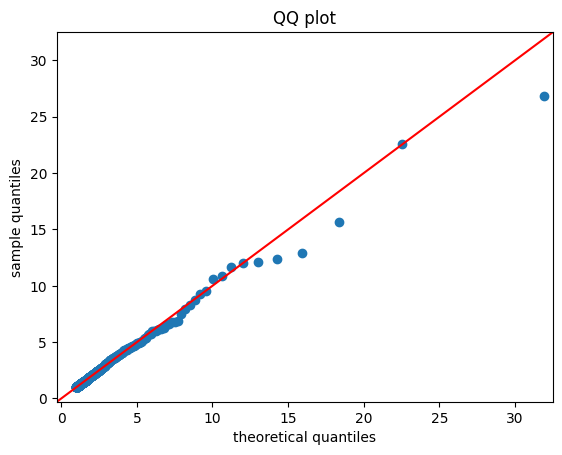

In [157]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()